In [1]:
#pip install umap-learn

In [2]:
#pip install anndata

In [3]:
#pip install scipy

In [4]:
#pip install anndata

In [5]:
#pip install pydeseq2

In [57]:
#pip install adjustText

In [121]:
import pandas as pd
import glob
import re
import xml.etree.ElementTree as et
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import umap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import pandas as pd
from mpl_toolkits.mplot3d import Axes3D

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.utils import load_example_data
from pydeseq2.ds import DeseqStats
from sklearn.preprocessing import StandardScaler
from adjustText import adjust_text
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import train_test_split


# Introduction

This notebook documents the analysis of RNA-Seq data from post-mortem brain cortex biopsies of individuals diagnosed with Amyotrophic Lateral Sclerosis (ALS) and healthy controls. The primary objective is to identify biomarkers associated with ALS by examining differentially expressed genes (DEGs) between these two groups. This analysis includes preprocessing steps, statistical methods such as differential expression analysis using DESeq2, and various data visualization techniques like PCA, t-SNE, and volcano plots. The results aim to provide insight into the molecular pathways implicated in ALS and potentially identify novel biomarkers for the disease.

# Step 1 - Data Preprocessing #

## Gather RNA Counts ##

In [7]:
path = "./Data" 

In [8]:
class DataPreprocessing:
    def __init__(self, data_path):
        self.data_path = data_path
        self.data_matrix = None

    def load_data(self):
        """Load RNA count data from all txt files and consolidate into a dataframe."""
        pd_list = []  # List to temporarily store all dataframes (one for each file)

        for fname in glob.glob(self.data_path + "/*.txt"):
            df = self._load_and_process_file(fname)
            pd_list.append(df)  # Add the current dataframe to the list

        self.data_matrix = pd.concat(pd_list, axis = 1)  # Concatenate all dataframes into one
        self.data_matrix = self.data_matrix.transpose()  # Transpose the dataframe (samples x genes)

    def _load_and_process_file(self, fname):
        """Load and process a single file."""
        try:
            df = pd.read_table(fname)  # Load the data into a dataframe
            sample_name = re.search("GSM\d+", fname).group()  # Extract sample name from file name
            df.rename(index=df["gene/TE"], inplace=True)  # Rename the rows using gene names
            df.drop(columns=df.columns[0], axis=1, inplace=True)  # Drop the first column containing the gene name
            df.rename(columns={df.columns[0]: sample_name}, inplace=True)  # Rename the column with the sample name
            return df
        except Exception as e:
            print(f"Error processing file {fname}: {e}")
            return pd.DataFrame()  # Return an empty dataframe in case of error

    def validate_data(self):
        """Validate that the dataframe has no missing or erroneous data."""
        if self.data_matrix is None:
            raise ValueError("Data matrix is not loaded yet.")

        missing_values = self.data_matrix.isnull().sum().sum()  # Count missing values
        if missing_values > 0:
            print(f"Warning: {missing_values} missing values in the dataset.")
        else:
            print("No missing values found.")

        # Additional validation checks can be added here

    def get_data(self):
        """Return the loaded and processed data."""
        if self.data_matrix is None:
            raise ValueError("Data matrix is not loaded yet.")
        return self.data_matrix


In [9]:
data_processor = DataPreprocessing("./Data")

In [10]:
data_processor.load_data()

In [11]:
data_processor.validate_data()

No missing values found.


In [12]:
data = data_processor.get_data()

In [13]:
data

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2MP1,A3GALT2,A4GALT,A4GNT,...,X6B_LINE:CR1:LINE,X7A_LINE:CR1:LINE,X7B_LINE:CR1:LINE,X7C_LINE:CR1:LINE,X7D_LINE:CR1:LINE,X8_LINE:CR1:LINE,X9_LINE:L1:LINE,Zaphod2:hAT-Tip100:DNA,Zaphod3:hAT-Tip100:DNA,Zaphod:hAT-Tip100:DNA
GSM3533230,42,149,0,3327,101,78,4,0,67,0,...,986,2218,2096,1120,84,556,134,570,2045,2446
GSM3533231,25,107,2,1787,153,109,2,1,25,0,...,1216,2373,2001,1144,118,582,153,552,2057,2279
GSM3533232,20,95,0,1830,121,127,1,1,11,0,...,905,2018,1815,1011,84,571,126,479,1659,1778
GSM3533233,22,101,0,2131,142,143,5,1,36,0,...,935,2278,2032,1198,97,562,132,540,2032,2135
GSM3533234,22,102,0,1706,83,178,1,3,31,0,...,966,2295,1993,1152,96,582,124,539,1742,1939
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM3533401,23,113,0,2130,72,71,2,3,21,0,...,553,1243,1089,658,72,320,73,311,1102,1169
GSM3533402,134,300,0,6077,171,42,8,5,225,0,...,719,1988,1691,966,119,460,109,399,1619,1724
GSM3533403,64,290,0,4752,118,174,8,2,135,0,...,623,1466,1246,726,61,358,107,347,1284,1469
GSM3533404,124,332,0,3516,141,173,3,2,192,0,...,743,1846,1680,936,110,479,120,503,1646,1839


In [14]:
data.shape

(176, 28953)

## Gather Sample Annotations ##

In [15]:


# Update the Sample class to include all annotations, including Subject_id
class Sample:
    def __init__(self, sample_id=None, sample_group=None, tissue_type=None, cns_subregion=None, subject_id=None):
        # Initialize the attributes of the Sample class
        self.sample_id = sample_id
        self.sample_group = sample_group
        self.tissue_type = tissue_type
        self.cns_subregion = cns_subregion
        self.subject_id = subject_id  # Add subject_id as an attribute
         

    # Getter for Sample_id
    def get_sample_id(self):
        return self.sample_id
    
    # Getter for Sample_group
    def get_sample_group(self):
        return self.sample_group

    # Getter for Tissue_type
    def get_tissue_type(self):
        return self.tissue_type

    # Getter for Cns_subregion
    def get_cns_subregion(self):
        return self.cns_subregion
    
    # Getter for Subject_id
    def get_subject_id(self):
        return self.subject_id  # Getter for Subject_id

    # Setter for Sample_id
    def set_sample_id(self, sample_id):
        self.sample_id = sample_id

    # Setter for Sample_group
    def set_sample_group(self, sample_group):
        self.sample_group = sample_group

    # Setter for Tissue_type
    def set_tissue_type(self, tissue_type):
        self.tissue_type = tissue_type

    # Setter for Cns_subregion
    def set_cns_subregion(self, cns_subregion):
        self.cns_subregion = cns_subregion
    
    # Setter for Subject_id
    def set_subject_id(self, subject_id):
        self.subject_id = subject_id  # Setter for Subject_id


# Initialize an empty list to store sample objects
samples = []

# Parse the XML file
xtree = et.parse('./Data/GSE124439_family.xml')  # Load and parse the XML file
xroot = xtree.getroot()  # Get the root of the XML tree to start the exploration

# Iterate through each "Sample" element in the XML
for sample in xroot.iter("{http://www.ncbi.nlm.nih.gov/geo/info/MINiML}Sample"):
    # Extract the Sample ID from the XML element attribute
    temp_sample_id = sample.attrib.get('iid', None)
    
    # Initialize default values for the sample annotations
    temp_sample_group = None
    temp_tissue_type = None
    temp_cns_subregion = None
    temp_subject_id = None  # Initialize Subject_id
    
    # Iterate through the "Characteristics" elements for the current sample
    for characteristics in sample.iter("{http://www.ncbi.nlm.nih.gov/geo/info/MINiML}Characteristics"):
        tag = characteristics.attrib.get("tag")  # Get the tag attribute for each Characteristics element
        
        # Assign values based on the tag
        if tag == "sample group":
            temp_sample_group = characteristics.text.strip().replace('\n', '')  # Clean and assign the sample group
        elif tag == "tissue type":
            temp_tissue_type = characteristics.text.strip().replace('\n', '')  # Clean and assign the tissue type
        elif tag == "cns subregion":
            temp_cns_subregion = characteristics.text.strip().replace('\n', '')  # Clean and assign the CNS subregion
        elif tag == "subject id":
            temp_subject_id = characteristics.text.strip().replace('\n', '')  # Clean and assign the Subject_id

    # Create a Sample object and set its values using the setters
    sample_obj = Sample()  # Create an instance of the Sample class
    sample_obj.set_sample_id(temp_sample_id)  # Set the Sample ID using the setter
    sample_obj.set_sample_group(temp_sample_group)  # Set the Sample Group using the setter
    sample_obj.set_tissue_type(temp_tissue_type)  # Set the Tissue Type using the setter
    sample_obj.set_cns_subregion(temp_cns_subregion)  # Set the CNS Subregion using the setter
    sample_obj.set_subject_id(temp_subject_id)  # Set the Subject ID using the setter
    
    # Add the Sample object to the list of samples
    samples.append(sample_obj)

# Now that we have a list of Sample objects, convert them into a DataFrame
data_annotation = pd.DataFrame([{
    'Sample_id': sample.get_sample_id(),  # Get the Sample ID using the getter
    'Sample_group': sample.get_sample_group(),  # Get the Sample Group using the getter
    'Tissue_type': sample.get_tissue_type(),  # Get the Tissue Type using the getter
    'Cns_subregion': sample.get_cns_subregion(),  # Get the CNS Subregion using the getter
    'Subject_id': sample.get_subject_id()  # Get the Subject ID using the getter
} for sample in samples])  # Iterate over all sample objects and extract the data

# Display the resulting DataFrame
data_annotation

,Sample_id,Sample_group,Tissue_type,Cns_subregion,Subject_id
0,GSM3533230,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUEL133AK6
1,GSM3533231,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUYV496XLP
2,GSM3533232,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUZU200WEQ
3,GSM3533233,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUME287RK2
4,GSM3533234,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUEC006FND
...,...,...,...,...,...
171,GSM3533401,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUMY028JH4
172,GSM3533402,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUXR145UBL
173,GSM3533403,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUKN209FNW
174,GSM3533404,ALS Spectrum MND,post-mortem tissue,Frontal Cortex,NEUUF289NRL


## Create Initial Preprocessing Function ##

We created functions in both sample and ALS_RNAseq classes

In [16]:
class ALS_RNAseq:
    def __init__(self, data_matrix, annotations):
        """
        Initialize the ALS_RNAseq object with the data matrix and annotations.
        
        data_matrix: pandas DataFrame where rows are samples and columns are genes.
        annotations: pandas DataFrame with sample annotations such as Sample_group, Source, etc.
        """
        self.__data_matrix = data_matrix  # Private attribute for storing the gene expression data
        self.__annotations = annotations  # Private attribute for storing sample annotations
        
        # Descriptive statistics will be computed during initialization
        self.__stats = self.calculate_descriptive_statistics()

    def get_data_matrix(self):
        return self.__data_matrix

    def get_annotations(self):
        return self.__annotations

    def calculate_descriptive_statistics(self):
        """
        Calculate mean, median, and standard deviation for each sample.
        Returns a DataFrame containing the statistics for each sample.
        """
        # Check if the data matrix is a valid pandas DataFrame
        if isinstance(self.__data_matrix, pd.DataFrame):
            stats = pd.DataFrame(index=self.__data_matrix.index)
            stats['mean'] = self.__data_matrix.mean(axis=1)
            stats['median'] = self.__data_matrix.median(axis=1)
            stats['std_dev'] = self.__data_matrix.std(axis=1)
            return stats
        else:
            raise ValueError("The data matrix should be a pandas DataFrame.")

    def summarize_annotations(self):
        """
        Summarize the annotation data: counts for 'Disease Group', 'Source', 'Samples per Individual', and 'CNS Subregion'.
        """
        disease_group_counts = self.__annotations['Sample_group'].value_counts()
        source_counts = self.__annotations['Tissue_type'].value_counts()

        # Count samples per individual (assuming a column 'Subject_id')
        samples_per_individual = self.__annotations['Subject_id'].value_counts()

        # Count samples per CNS subregion
        cns_subregion_counts = self.__annotations['Cns_subregion'].value_counts()

        return disease_group_counts, source_counts, samples_per_individual, cns_subregion_counts

    def print_raw_data_and_stats(self):
        # Print the raw data matrix (gene expression values)
        print("Data Matrix (Gene Expression Data):")
        print(self.__data_matrix)
        
        # Print the calculated descriptive statistics
        print("\nDescriptive Statistics:")
        print(self.__stats)
    def plot_disease_group_distribution(self):
        """
        Plot the distribution of samples across disease groups using a bar chart.
        """
        disease_group_counts, _, _, _ = self.summarize_annotations()  # Updated to accept 4 values

        plt.figure(figsize=(8, 6))
        sns.barplot(x=disease_group_counts.index, y=disease_group_counts.values, palette='viridis')
        plt.title('Sample Distribution by Disease Group')
        plt.xlabel('Disease Group')
        plt.ylabel('Sample Count')
        plt.xticks(rotation=45)
        plt.show()

    def plot_source_distribution(self):
        """
        Plot the distribution of samples across sample sources using a bar chart.
        """
        _, _, _, cns_subregion_counts = self.summarize_annotations()  # Update to accept 4 values

        plt.figure(figsize=(8, 6))
        sns.barplot(x=cns_subregion_counts.index, y=cns_subregion_counts.values, palette='viridis')
        plt.title('Sample Distribution by CNS Subregion')
        plt.xlabel('CNS Subregion')
        plt.ylabel('Sample Count')
        plt.xticks(rotation=45)
        plt.show()


    def plot_statistics_histograms(self):
        """
        Plot histograms for the mean, median, and standard deviation of gene expression across samples.
        """
        # Plot histograms for the descriptive statistics
        plt.figure(figsize=(12, 6))

        # Histogram for Mean Expression
        plt.subplot(1, 3, 1)
        plt.hist(self.__stats['mean'], bins=10, color='blue', alpha=0.7)
        plt.title('Histogram of Means')
        plt.xlabel('Mean Expression')
        plt.ylabel('Frequency')

        # Histogram for Median Expression
        plt.subplot(1, 3, 2)
        plt.hist(self.__stats['median'], bins=10, color='green', alpha=0.7)
        plt.title('Histogram of Medians')
        plt.xlabel('Median Expression')
        plt.ylabel('Frequency')

        # Histogram for Standard Deviation
        plt.subplot(1, 3, 3)
        plt.hist(self.__stats['std_dev'], bins=10, color='red', alpha=0.7)
        plt.title('Histogram of Standard Deviations')
        plt.xlabel('Standard Deviation of Expression')
        plt.ylabel('Frequency')

        plt.tight_layout()
        plt.show()

    def summary_statistics(self):
        """
        Return the summary statistics: mean, median, and standard deviation for each sample.
        """
        return self.__stats

    def __str__(self):
        """
        Custom string representation of the ALS_RNAseq object.
        Provides a quick overview of the dataset.
        """
        # La méthode summarize_annotations retourne maintenant 4 éléments
        disease_group_counts, source_counts, samples_per_individual, _ = self.summarize_annotations()  # On accepte 4 valeurs

        return (f"ALS_RNAseq Dataset Summary:\n"
                f"Number of samples: {len(self.__data_matrix)}\n"
                f"Disease Groups: {disease_group_counts}\n"
                f"Sources: {source_counts}\n"
                f"Samples per individual: {samples_per_individual}\n"
                f"Descriptive statistics: Mean, Median, and Standard Deviation for each sample.")
    def perform_differential_expression_analysis(self):
        """
        Perform differential expression analysis using DESeq2 (PyDESeq2).
        This method assumes data_matrix and annotations are correctly formatted.
        """
        # Prepare the data for DESeq2
        count_data = self.__data_matrix
        col_data = self.__annotations[['Sample_group']]  # Assuming 'Sample_group' exists in annotations

        # Initialize DESeq2
        dds = DESeqDataSetFromMatrix(countData=count_data, colData=col_data, design="~ Sample_group")

        # Perform DESeq2 analysis
        dds = DESeq(dds)

        # Retrieve the results from DESeq2
        results = r['results'](dds)
        
        # Store the results in the class
        self.__deseq_results = pd.DataFrame(r['as.data.frame'](results))

    def get_differential_expression_results(self):
        """
        Return the results of the differential expression analysis.
        """
        return self.__deseq_results


# Step 2 #

##   Sample Description  ##

In [17]:
# Initialize the ALS_RNAseq object with data_matrix and annotations
als_rnaseq = ALS_RNAseq(data, data_annotation)
# Print the ALS_RNAseq object to check the summary
print(als_rnaseq)

ALS_RNAseq Dataset Summary:
Number of samples: 176
Disease Groups: Sample_group
ALS Spectrum MND                145
Non-Neurological Control         17
Other Neurological Disorders     14
Name: count, dtype: int64
Sources: Tissue_type
post-mortem tissue    176
Name: count, dtype: int64
Samples per individual: Subject_id
NEUEL133AK6    3
NEUUE532LFF    3
NEUEF397VVN    3
NEUWZ373ZHA    3
NEUAT369TG5    3
              ..
NEUZB953VCD    1
NEUNL974RU6    1
JHU 75         1
JHU 77         1
NEUPU334DL1    1
Name: count, Length: 95, dtype: int64
Descriptive statistics: Mean, Median, and Standard Deviation for each sample.


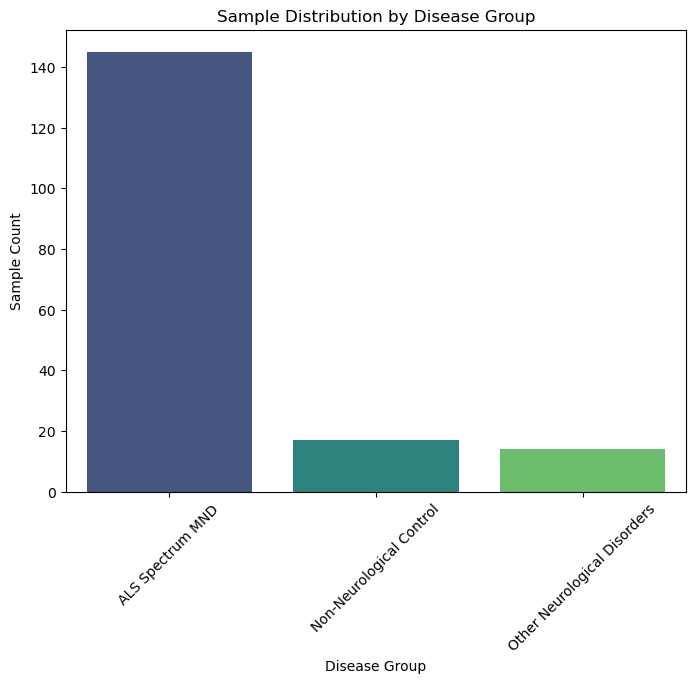

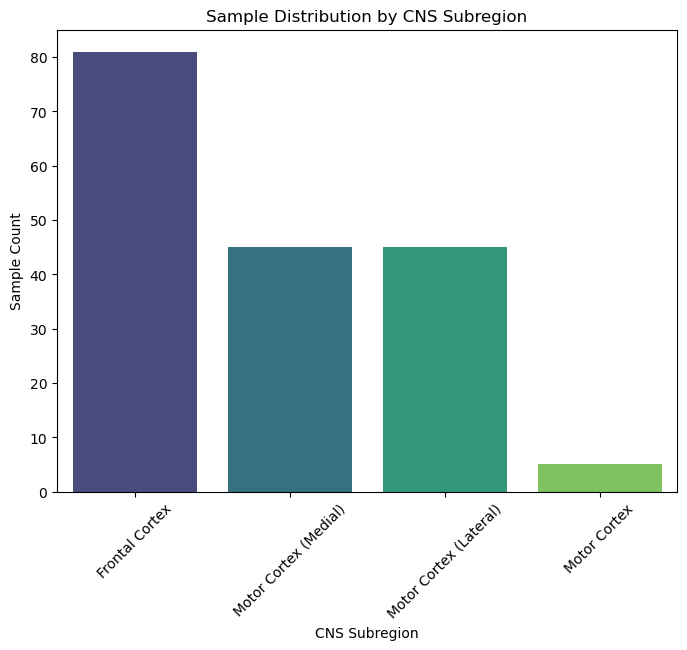

In [18]:
# Perform the required visualizations and descriptive statistics
als_rnaseq.plot_disease_group_distribution()  # Disease group distribution : Bar Charts
als_rnaseq.plot_source_distribution()  # Source distribution

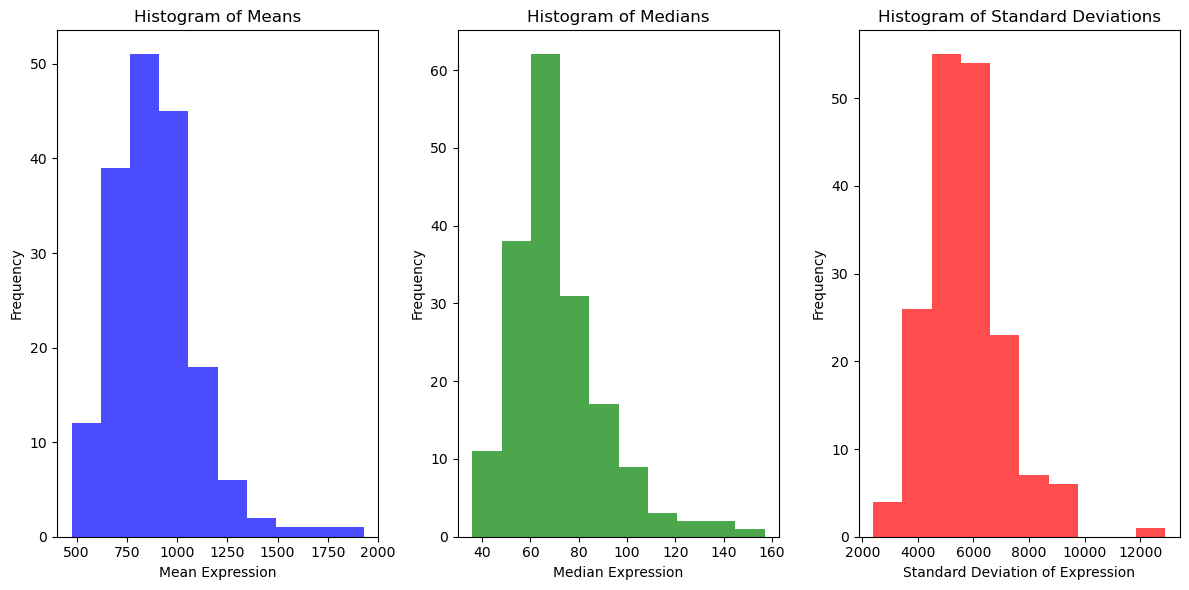

In [19]:
als_rnaseq.plot_statistics_histograms()  # Histograms for mean, median, std deviation

## RNA Counts Description:


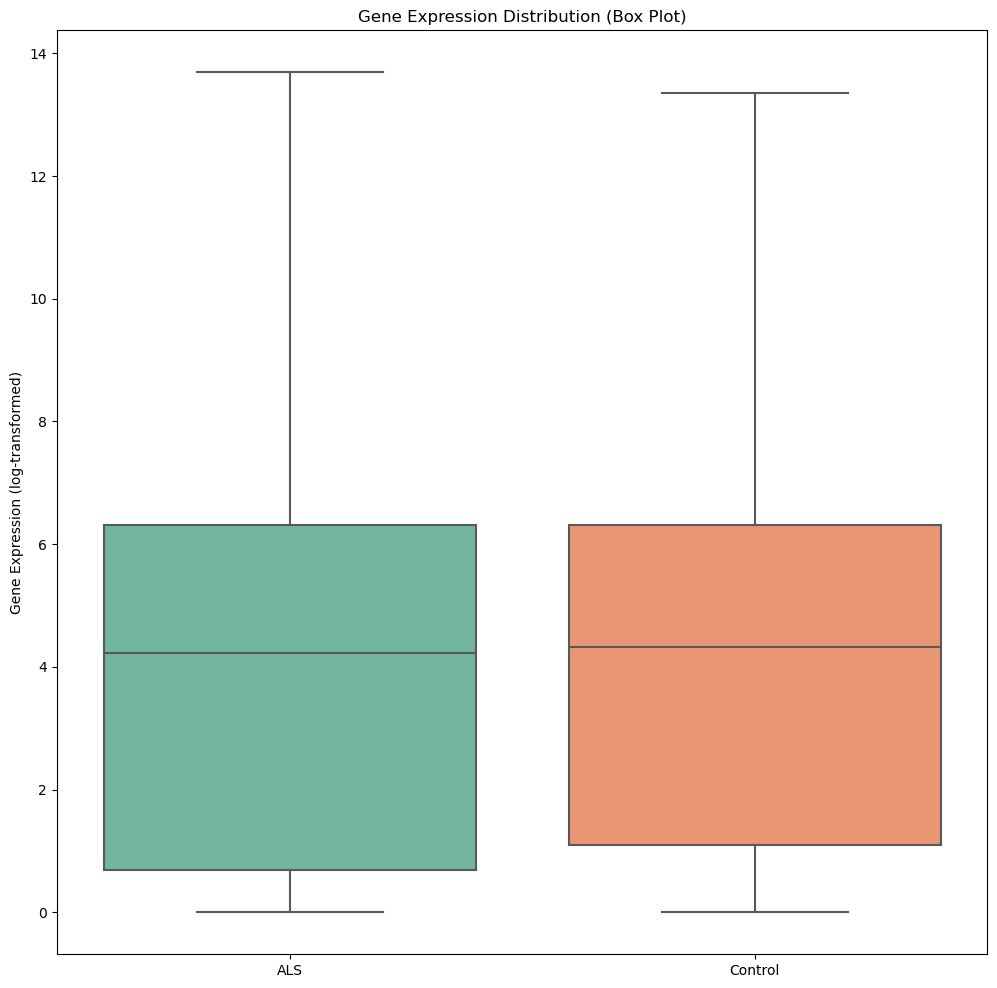

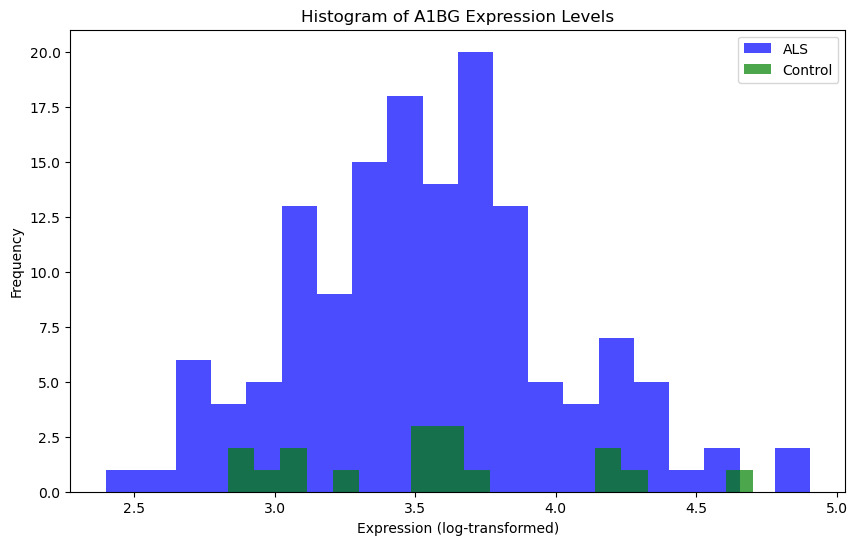

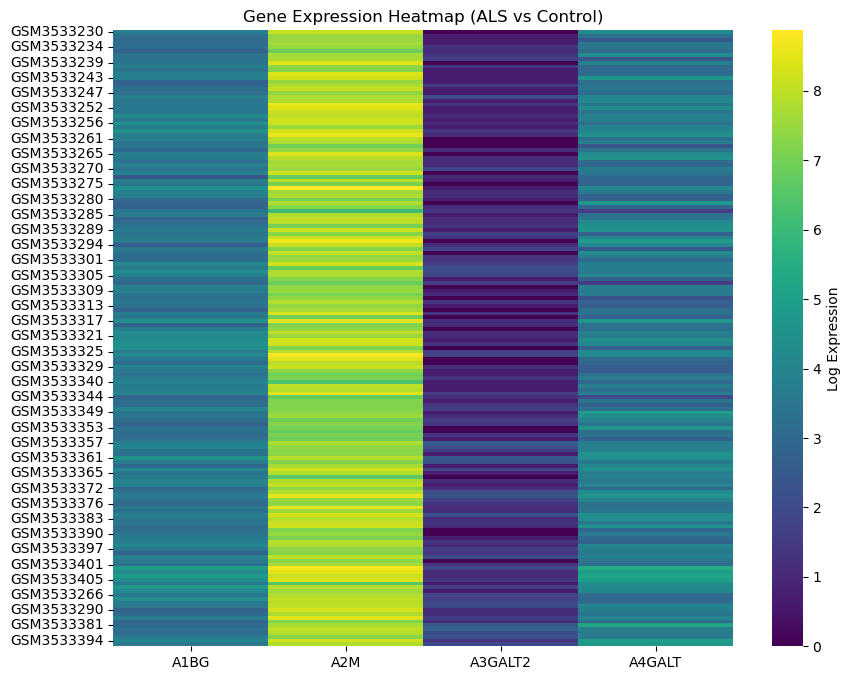

ALS Samples Descriptive Stats:
                            mean       50%       std
A1BG                    3.544560  3.526361  0.463248
A1BG-AS1                4.716765  4.700480  0.376726
A1CF                    0.106597  0.000000  0.320918
A2M                     7.679847  7.706613  0.537366
A2M-AS1                 4.594764  4.564348  0.330012
...                          ...       ...       ...
X8_LINE:CR1:LINE        6.097702  6.102559  0.276633
X9_LINE:L1:LINE         4.679316  4.682131  0.297370
Zaphod2:hAT-Tip100:DNA  5.991846  6.030685  0.308282
Zaphod3:hAT-Tip100:DNA  7.305078  7.340187  0.298965
Zaphod:hAT-Tip100:DNA   7.420245  7.457609  0.285355

[28953 rows x 3 columns]


In [20]:


# Assuming data_matrix is the gene expression data and data_annotation contains the annotations
# Log-transform the data to stabilize variance
log_data_matrix = np.log1p(data)

# 1. Descriptive Statistics (mean, median, std) for each gene across all samples
gene_stats = log_data_matrix.describe().loc[['mean', '50%', 'std']].transpose()
gene_stats.rename(columns={'50%': 'median'}, inplace=True)

# 2. Create subsets for ALS patients and control groups
als_samples = data_annotation[data_annotation['Sample_group'] == 'ALS Spectrum MND']
control_samples = data_annotation[data_annotation['Sample_group'] == 'Non-Neurological Control']

# ALS and Control Data Subsets
als_data = log_data_matrix.loc[als_samples['Sample_id'], :]
control_data = log_data_matrix.loc[control_samples['Sample_id'], :]

# 3. Visualizations

# Box Plot for ALS vs Control for each gene
plt.figure(figsize=(12, 12))
sns.boxplot(data=[als_data, control_data], palette="Set2")
plt.xticks([0, 1], ['ALS', 'Control'])
plt.title('Gene Expression Distribution (Box Plot)')
plt.ylabel('Gene Expression (log-transformed)')
plt.show()

# Histograms for a specific gene (example gene 'A1BG') across ALS and Control
plt.figure(figsize=(10, 6))
plt.hist(als_data['A1BG'], bins=20, alpha=0.7, label='ALS', color='blue')
plt.hist(control_data['A1BG'], bins=20, alpha=0.7, label='Control', color='green')
plt.title('Histogram of A1BG Expression Levels')
plt.xlabel('Expression (log-transformed)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Heatmap for selected genes across ALS and Control groups
selected_genes = ['A1BG', 'A2M', 'A3GALT2', 'A4GALT']  # We can modify the list of selected genes
heatmap_data = pd.concat([als_data[selected_genes], control_data[selected_genes]], axis=0)

plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, cmap='viridis', annot=False, cbar_kws={'label': 'Log Expression'})
plt.title('Gene Expression Heatmap (ALS vs Control)')
plt.show()

# Summary of Descriptive Statistics for ALS and Control groups
als_stats = als_data.describe().loc[['mean', '50%', 'std']].transpose()
control_stats = control_data.describe().loc[['mean', '50%', 'std']].transpose()

print("ALS Samples Descriptive Stats:")
print(als_stats)



 Gene statistics:
                               Mean  Median          Std
A1BG                      38.062500    34.0    20.511225
A1BG-AS1                 118.568182   108.5    48.137849
A1CF                       0.170455     0.0     0.662835
A2M                     2455.403409  2286.5  1278.351971
A2M-AS1                  102.568182    94.5    35.553998
...                             ...     ...          ...
X8_LINE:CR1:LINE         462.647727   448.0   129.147228
X9_LINE:L1:LINE          110.863636   107.0    33.597511
Zaphod2:hAT-Tip100:DNA   415.931818   409.5   122.379157
Zaphod3:hAT-Tip100:DNA  1555.630682  1562.5   462.496696
Zaphod:hAT-Tip100:DNA   1735.556818  1733.0   490.915096

[28953 rows x 3 columns]


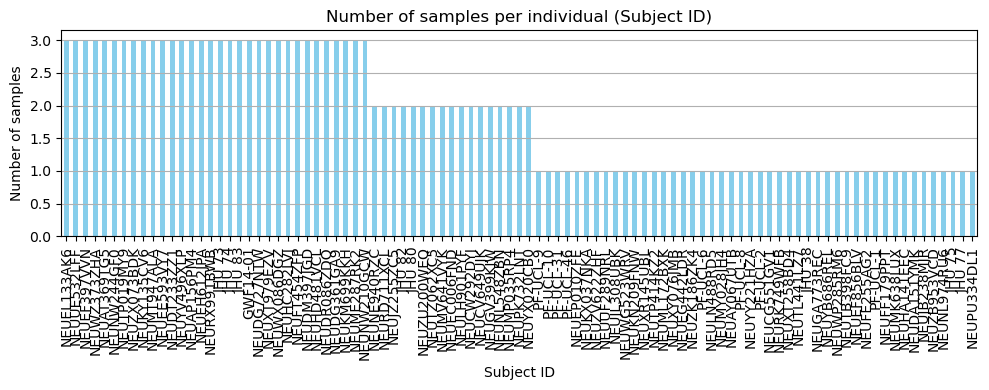

 Global summary table:


,Sample_group,Cns_subregion,Subject_id,Count
0,ALS Spectrum MND,Frontal Cortex,JHU 74,2
1,ALS Spectrum MND,Frontal Cortex,JHU 75,1
2,ALS Spectrum MND,Frontal Cortex,JHU 77,1
3,ALS Spectrum MND,Frontal Cortex,JHU 80,1
4,ALS Spectrum MND,Frontal Cortex,NEUAP156PM4,1
5,ALS Spectrum MND,Frontal Cortex,NEUAT369TG5,1
6,ALS Spectrum MND,Frontal Cortex,NEUAY067UTB,1
7,ALS Spectrum MND,Frontal Cortex,NEUCV649UJK,1
8,ALS Spectrum MND,Frontal Cortex,NEUCW292DYJ,1
9,ALS Spectrum MND,Frontal Cortex,NEUDG361GA9,1


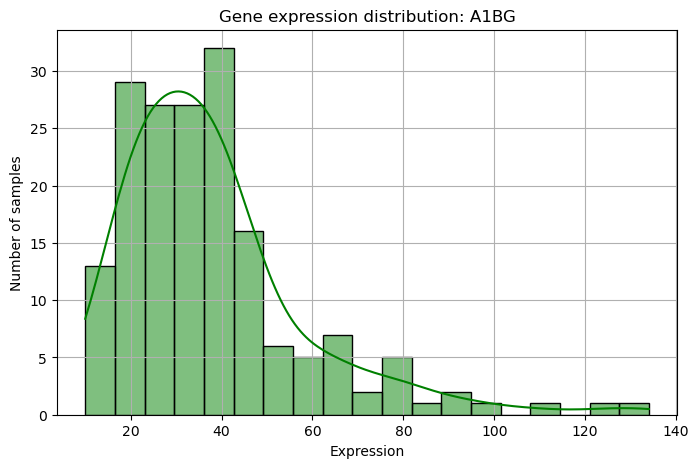

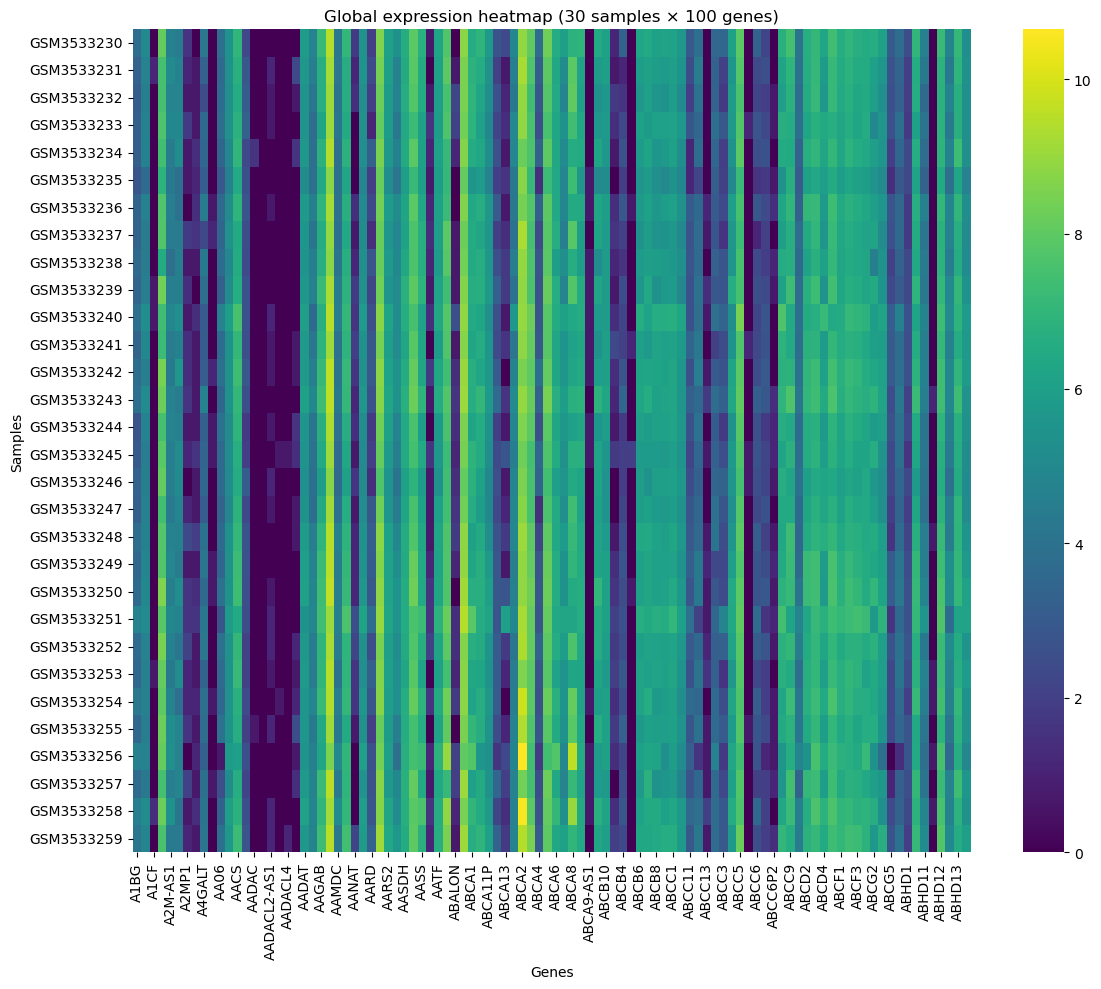

In [145]:
# ---------------------------------------------
#  STATS BY GENE (mean, median, std)
# ---------------------------------------------
gene_stats = pd.DataFrame({
    'Mean': data.mean(axis=0),
    'Median': data.median(axis=0),
    'Std': data.std(axis=0)
})
print(" Gene statistics:")
print(gene_stats)

# ---------------------------------------------
#  SAMPLE COUNT BY INDIVIDUAL (Subject_id)
# ---------------------------------------------
plt.figure(figsize=(10, 4))
subject_counts = data_annotation['Subject_id'].value_counts()
subject_counts.plot(kind='bar', color='skyblue')
plt.title("Number of samples per individual (Subject ID)")
plt.xlabel("Subject ID")
plt.ylabel("Number of samples")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# ---------------------------------------------
#  GLOBAL SUMMARY TABLE (group/source/individual)
# ---------------------------------------------
summary_table = data_annotation.groupby(['Sample_group', 'Cns_subregion', 'Subject_id']).size().reset_index(name='Count')
print(" Global summary table:")
display(summary_table.head(10))  # Display the first 10 rows

# ---------------------------------------------
#  GENE EXPRESSION HISTOGRAM (example with the first gene)
# ---------------------------------------------
gene_example = data.columns[0]  # First gene by default
plt.figure(figsize=(8, 5))
sns.histplot(data[gene_example], kde=True, color='green')
plt.title(f"Gene expression distribution: {gene_example}")
plt.xlabel('Expression')
plt.ylabel('Number of samples')
plt.grid(True)
plt.show()

# ---------------------------------------------
#  GLOBAL HEATMAP (for a subset of 30 samples, 100 genes)
# ---------------------------------------------
subset_data = log_data_matrix.iloc[:30, :100]  # Reduced for readability
plt.figure(figsize=(12, 10))
sns.heatmap(subset_data, cmap="viridis")
plt.title("Global expression heatmap (30 samples × 100 genes)")
plt.xlabel("Genes")
plt.ylabel("Samples")
plt.tight_layout()
plt.show()


This descriptive step has highlighted several key points to consider for future analyses:

A high inter-gene variability indicating potential candidates for differential analysis.

A potential bias related to the over-representation of certain individuals compared to others, or related to sampling sites, which may impact the results.

An imbalanced distribution of brain regions and disease groups, requiring thorough validation through PCA and subsequent multivariate analyses.

The heatmap and histograms suggest some variability between the ALS and Control groups. Additionally, certain genes already appear as strong potential candidates for our study. It is important to focus on genes that show both high expression (green-yellow) and significant variability (high standard deviation).









# Step 3 : PCA 

## SubStep 1 - Standardizing the Data:
Before performing PCA, we standardize the data. 

Standardization is essential for PCA because it ensures each feature (gene) has a mean of 0 and a standard deviation of 1. 

This step ensures that PCA will not be biased by the different scales of the features.

In [22]:

# Standardize the data (mean = 0, standard deviation = 1)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_processor.get_data())


## SubStep 2 - Cumulative Explained Variance Plot:
We  plot the cumulative explained variance to see how much variance is explained as we add more principal components.


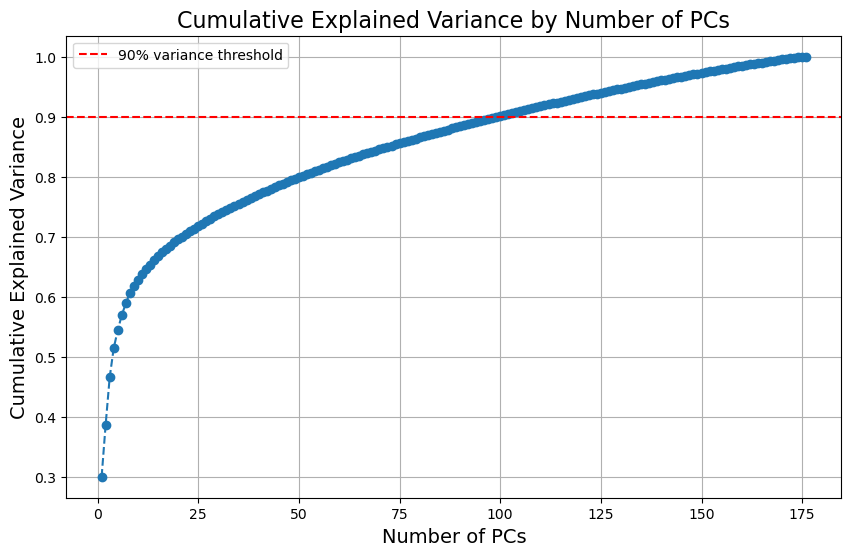

Optimal number of PCs chosen (90% threshold): 100


In [23]:
# PCA without any initial limitation (full PCA)
pca_full = PCA().fit(scaled_data)  # Perform PCA on the scaled data

# Cumulative variance explained
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)  # Calculate the cumulative sum of explained variance ratio for each principal component

# Clear plot of cumulative variance with a threshold at 90%
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o', linestyle='--')  # Plot the cumulative variance explained vs the number of PCs
plt.xlabel('Number of PCs', fontsize=14)  # Label for x-axis
plt.ylabel('Cumulative Explained Variance', fontsize=14)  # Label for y-axis
plt.title('Cumulative Explained Variance by Number of PCs', fontsize=16)  # Title of the plot
plt.axhline(y=0.9, color='r', linestyle='--', label='90% variance threshold')  # Add a horizontal line at 90% cumulative variance
plt.legend()  # Display the legend
plt.grid(True)  # Show gridlines for better readability
plt.show()  # Display the plot

# Select the optimal number of PCs (threshold of 90%)
optimal_pcs = np.argmax(cum_variance >= 0.90) + 1  # Find the first principal component where the cumulative variance exceeds 90%
print(f"Optimal number of PCs chosen (90% threshold): {optimal_pcs}")  # Print the optimal number of PCs based on the 90% variance threshold


In [24]:
# Final PCA with the rigorously chosen optimal number of PCs
pca_optimal = PCA(n_components=optimal_pcs)  # Create a PCA object with the optimal number of components
pca_result = pca_optimal.fit_transform(scaled_data)  # Perform PCA and get the transformed data (principal components)

# Explicitly preserve the original indices:
pca_df = pd.DataFrame(pca_result, 
                      columns=[f'PC{i+1}' for i in range(optimal_pcs)],  # Create column names for each principal component
                      index=data_processor.get_data().index)  # Preserve the original index of the data (samples)

pca_df['Group'] = data_annotation['Sample_group'].values  # Add the sample group information to the DataFrame


## SubStep 3 - Explained Variance:
We print out the explained variance for each of the first four principal components. The explained variance ratio indicates how much of the total variance is captured by each component. This helps us understand how well the PCA reduces the dimensionality.


 Explained Variance (ratio) of the first 4 PCs:
 - PC1 : 30.10%
 - PC2 : 8.69%
 - PC3 : 7.84%
 - PC4 : 4.86%


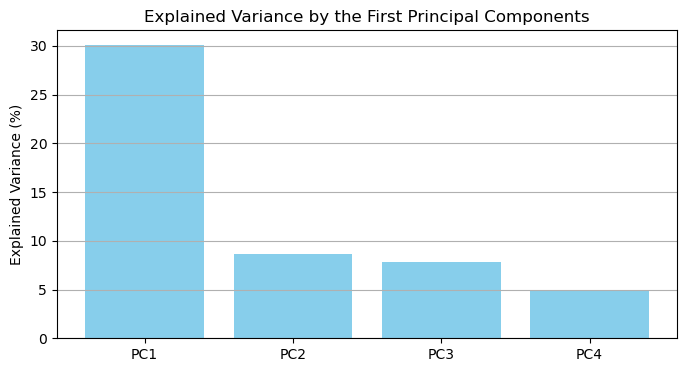

In [25]:
# Displaying the explained variance by the first 4 principal components
explained_variance_ratio = pca_optimal.explained_variance_ratio_  # Get the explained variance ratio for each principal component

# If we want to display only the first 4 PCs (even if we have more)
n_display = min(4, len(explained_variance_ratio))  # Set the number of PCs to display (maximum of 4)

print(" Explained Variance (ratio) of the first 4 PCs:")
for i in range(n_display):
    print(f" - PC{i+1} : {explained_variance_ratio[i]*100:.2f}%")  # Print the explained variance for each of the first 4 PCs

# Optional: graphical display
plt.figure(figsize=(8, 4))  # Set the size of the plot
plt.bar([f'PC{i+1}' for i in range(n_display)],  # Create labels for the bars (PC1, PC2, etc.)
        explained_variance_ratio[:n_display]*100,  # Use the explained variance ratios for the first 4 PCs (in percentage)
        color='skyblue')  # Set the color of the bars
plt.ylabel('Explained Variance (%)')  # Label for the y-axis
plt.title('Explained Variance by the First Principal Components')  # Title of the plot
plt.grid(True, axis='y')  # Add gridlines to the y-axis for better readability
plt.show()  # Display the plot


Analysis of the Graph:

The graph shows a typical "elbow" shape, where the first few components capture most of the variance.

After around 30-40 components, the cumulative explained variance flattens out, indicating that additional components contribute very little new information.

Based on this, we can choose a small number of components (e.g., the first 2-3 PCs) for further analysis.



## SubStep 5 - 2D PCA Visualization:


In SubStep 3, the explained variance ratio shows how much each component contributes to explaining the data. In our case, PC1 captures 28.8% of the variance, PC2 captures 9.8%, and PC3 captures 8.2%. Together, they account for a substantial portion of the variance (around 47%).

PC4, although it captures 4.9% of the variance, doesn't add much new information for the visualization and might be excluded to avoid overcomplicating the analysis.

We  visualize the first three pairs of principal components (PC1 vs PC2, PC1 vs PC3, PC2 vs PC3) in 2D scatter plots.

This helps us to see how the samples are distributed based on these components.

In [26]:
# PCA with only 4 components for visualization/outliers
pca_visu = PCA(n_components=4)  # Perform PCA with 4 components
pca_visu_result = pca_visu.fit_transform(scaled_data)  # Fit the PCA model and transform the data

# Creating a DataFrame with the 4 principal components and the corresponding sample groups
pca_visu_df = pd.DataFrame(
    pca_visu_result,  # PCA results (transformed data)
    columns=[f'PC{i+1}' for i in range(4)],  # Names for the columns (PC1, PC2, PC3, PC4)
    index=data_processor.get_data().index  # Retaining the original data index for reference
)

# Adding the sample group information to the DataFrame
pca_visu_df['Group'] = data_annotation['Sample_group'].values  # Attach the group labels (e.g., ALS, control) to the DataFrame


### Plot PC1 vs PC2 and  PC1 vs PC3 and PC2 vs PC3

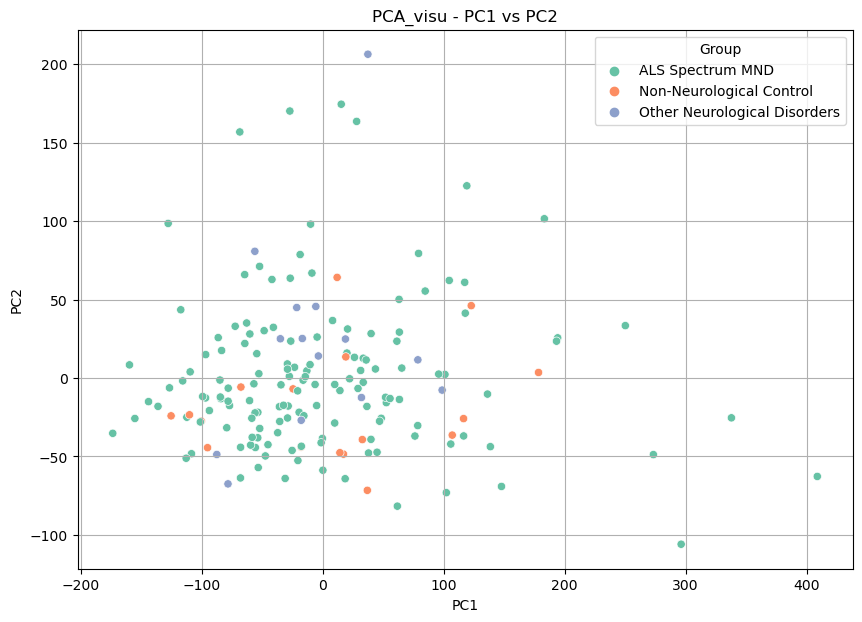

In [32]:
# 2D Visualization of PCA: PC1 vs PC2
plt.figure(figsize=(10,7))  # Set the figure size
sns.scatterplot(data=pca_visu_df, x='PC1', y='PC2', hue='Group', palette='Set2')  # Create a scatter plot with PC1 and PC2 on the axes, colored by sample group
plt.title('PCA_visu - PC1 vs PC2')  # Title for the plot
plt.grid(True)  # Display grid lines
plt.show()  # Show the plot



The PCA plot shows the distribution of samples based on the first two principal components, PC1 and PC2. ALS Spectrum MND (green) samples are primarily clustered in the middle-left, indicating a distinct gene expression pattern. Non-Neurological Control (orange) samples are more spread out, with some overlap with ALS, while Other Neurological Disorders (blue) samples show a scattered pattern across the plot, indicating similarities with both ALS and Non-Neurological Controls. The clustering suggests that the ALS group is more distinct, while the other two groups share more variability and overlap, which could indicate potential biological similarities. Further analysis with additional components may provide clearer separation.

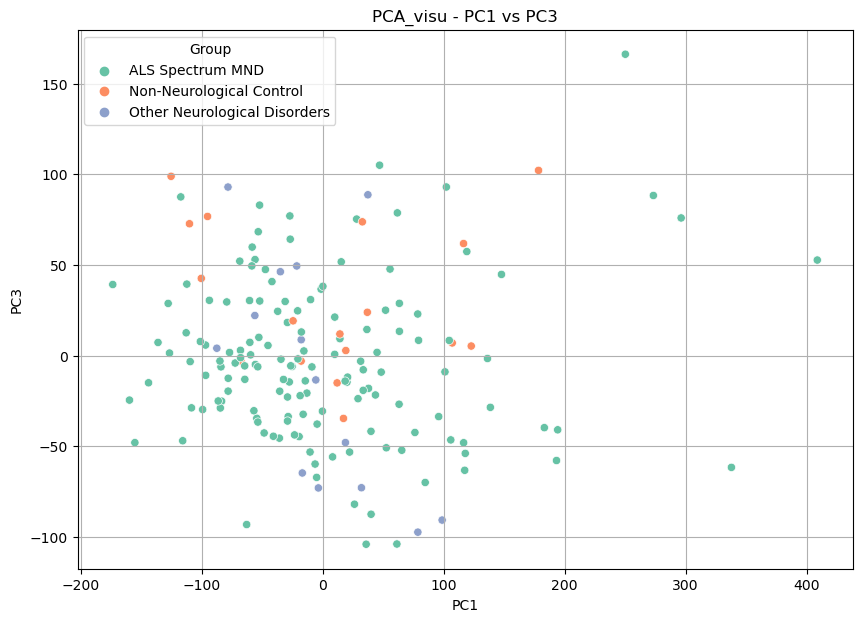

In [33]:
# 2D Visualization of PCA: PC1 vs PC3
plt.figure(figsize=(10,7))  # Set the figure size
sns.scatterplot(data=pca_visu_df, x='PC1', y='PC3', hue='Group', palette='Set2')  # Create a scatter plot with PC1 and PC3 on the axes, colored by sample group
plt.title('PCA_visu - PC1 vs PC3')  # Title for the plot
plt.grid(True)  # Display grid lines
plt.show()  # Show the plot

The PCA plot shows the distribution of ALS Spectrum MND (green), Non-Neurological Control (orange), and Other Neurological Disorders (blue) across Principal Components 1 (28.8% variance) and 3 (8.2% variance). ALS samples are more dispersed, particularly along PC1, while Non-Neurological Controls cluster more towards the right with some overlap with ALS. Other Neurological Disorders samples are scattered, overlapping with both ALS and control groups, indicating a shared but distinct gene expression profile. Overall, PC1 captures the largest variance, and PC3 offers finer differentiation within groups.


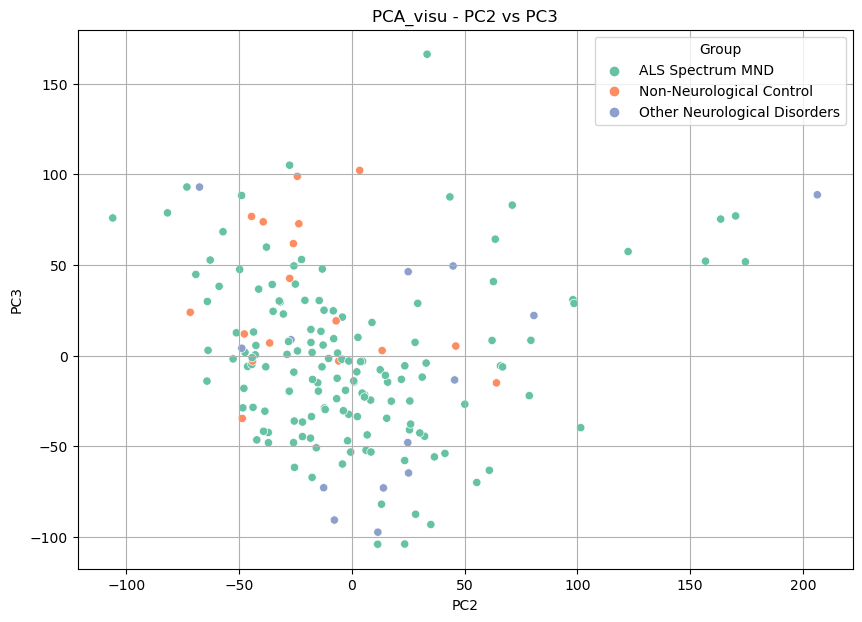

In [34]:
# 2D Visualization of PCA: PC2 vs PC3
plt.figure(figsize=(10,7))  # Set the figure size
sns.scatterplot(data=pca_visu_df, x='PC2', y='PC3', hue='Group', palette='Set2')  # Create a scatter plot with PC2 and PC3 on the axes, colored by sample group
plt.title('PCA_visu - PC2 vs PC3')  # Title for the plot
plt.grid(True)  # Display grid lines
plt.show()  # Show the plot


In this PCA plot, the samples are distributed across Principal Components 2 (9.8% variance) and 3 (8.2% variance). The ALS Spectrum MND (green) samples form a distinct cluster, mostly in the lower half, while the Non-Neurological Control (orange) samples are more spread across the lower-left area. The Other Neurological Disorders (blue) samples are scattered, overlapping with both ALS and control groups, indicating that they share some common characteristics but also exhibit distinct gene expression patterns.


## SubStep 6 - 3D PCA Visualization:
We  perform a 3D visualization using the first three principal components (PC1, PC2, and PC3). 

This allows us to observe the distribution of samples in three dimensions.


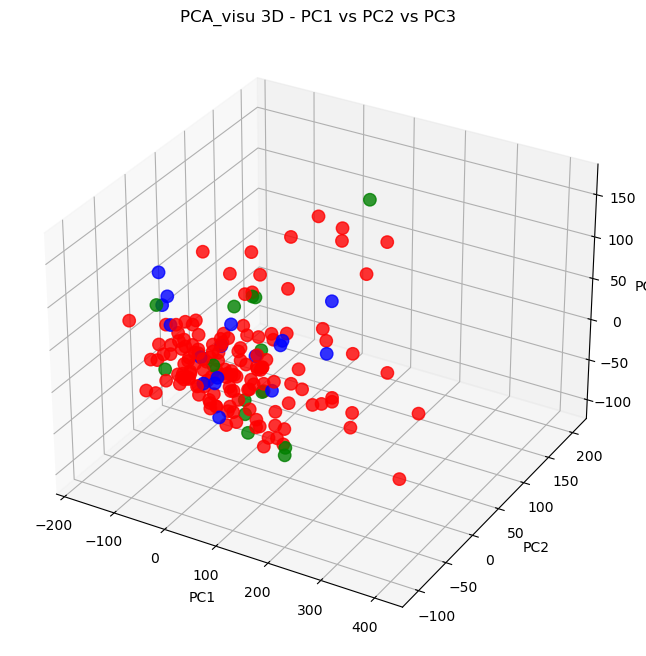

In [28]:
# Visualization 3D PCA_visu - PC1 vs PC2 vs PC3
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    pca_visu_df['PC1'], pca_visu_df['PC2'], pca_visu_df['PC3'],
    c=pca_visu_df['Group'].map({
        'ALS Spectrum MND': 'red',
        'Non-Neurological Control': 'blue',
        'Other Neurological Disorders': 'green'
    }),
    s=80, alpha=0.8
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA_visu 3D - PC1 vs PC2 vs PC3')
plt.show()


The 3D PCA plot shows the distribution of ALS Spectrum MND (red), Non-Neurological Control (blue), and Other Neurological Disorders (green) samples along the first three principal components. 

ALS samples are distinctly separated from controls, particularly along PC1, which explains 28.8% of the variance. 

Non-Neurological Controls are spread out but still distinct from ALS samples. 

Other Neurological Disorders show overlap with both ALS and control groups, indicating shared gene expression characteristics. 

Outliers, especially in the ALS and control groups, suggest potential experimental noise or significant biological variance. This visualization highlights the differences and similarities between the groups based on gene expression patterns.



## SubStep 7 - Outlier Detection:
We use the Euclidean distance to detect potential outliers. 

Outliers are samples that are far away from the rest of the data in the PCA space. 

We set a threshold to detect the top 5% of outliers based on the distance from the origin.


In [66]:
# Calculating the Euclidean distance in the PCA_visu space (4D)
pca_visu_df['Distance'] = np.sqrt(np.sum(pca_visu_df[['PC1', 'PC2', 'PC3', 'PC4']]**2, axis=1))  # Compute the Euclidean distance for each sample using the first 4 principal components

# Setting the threshold based on the mean + 2 standard deviations
mean_distance = pca_visu_df['Distance'].mean()  # Calculate the mean of the distances
std_distance = pca_visu_df['Distance'].std()    # Calculate the standard deviation of the distances
threshold = mean_distance + 2 * std_distance    # Set the threshold as the mean distance plus 2 times the standard deviation

# Detecting outliers based on the threshold
outliers_visu = pca_visu_df[pca_visu_df['Distance'] > threshold]  # Identify samples with distances greater than the threshold

# Printing the threshold and the number of detected outliers
print(f" Outlier threshold: {threshold:.2f} (μ + 2σ)")  # Display the threshold value
print(f"Total number of outliers detected: {outliers_visu.shape[0]}")  # Show the number of outliers
outliers_visu[['Group', 'Distance']]  # Print the group and distance of the outliers


 Outlier threshold: 223.30 (μ + 2σ)
Total number of outliers detected: 7


,Group,Distance
GSM3533251,Non-Neurological Control,229.855964
GSM3533299,Other Neurological Disorders,228.015045
GSM3533302,ALS Spectrum MND,345.754642
GSM3533361,ALS Spectrum MND,323.727234
GSM3533364,ALS Spectrum MND,427.472204
GSM3533402,ALS Spectrum MND,314.154625
GSM3533404,ALS Spectrum MND,305.365878


## SubStep 8 - Create Models (With and Without Outliers):


We now create two datasets:

With Outliers: The dataset including the outliers.

Without Outliers: The dataset after removing the detected outliers.


In [30]:
# Removing outliers from both the data and annotations
data_without_outliers = data_processor.get_data().drop(index=outliers_visu.index)  # Drop the rows of outliers from the data
annotation_without_outliers = data_annotation[~data_annotation['Sample_id'].isin(outliers_visu.index)]  # Remove the outliers' annotations using their indices

# Printing the summary of the optimized PCA (outliers removed)
print(f"""
 Optimized PCA summary (outliers definitively removed) :
- Optimal number of PCs chosen: {optimal_pcs}  
- Data with outliers: {scaled_data.shape[0]} samples  
- Data without outliers: {data_without_outliers.shape[0]} samples  
- Annotations without outliers: {annotation_without_outliers.shape[0]} samples  
""")



 Optimized PCA summary (outliers definitively removed) :
- Optimal number of PCs chosen: 100  
- Data with outliers: 176 samples  
- Data without outliers: 169 samples  
- Annotations without outliers: 169 samples  



Outliers Detected (According to 90th Percentile Threshold): The outliers are detected based on the 90th percentile distance. 


The samples with distances greater than this threshold are considered as outliers.


#### Conclusion:
PCA was used to reduce the dimensionality of the data and visualize the variance captured by each component.

2D and 3D visualizations helped identify how the samples are distributed based on the principal components.

Outlier detection was done using the Euclidean distance, and a threshold was set to identify the top 10% of outliers.

The data was split into two sets: one with the outliers and one without the outliers, for further analysis.



# Step 4 - tSNE and UMAP

In this section, we will first apply t-SNE to visualize the sample distribution by reducing the dimensionality of the dataset into two components. 

Then, we'll use UMAP for another dimensionality reduction and visualization, followed by a comparison of the results with PCA to analyze how these methods differ in capturing the relationships and patterns within the data.



## SubStep1 : t-SNE Analysis:

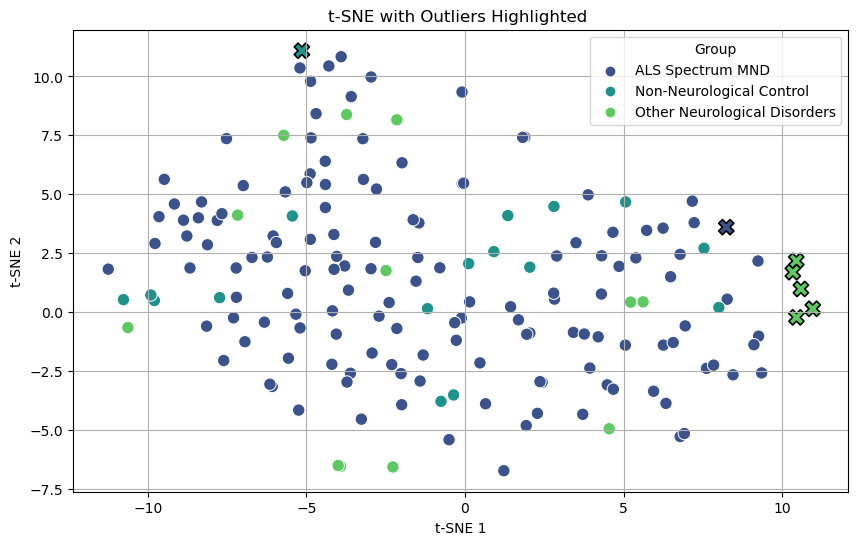

In [111]:
# Creating the DataFrame with groups and outlier flag
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(scaled_data)
tsne_df = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'], index=data_processor.get_data().index)
tsne_df['Group'] = data_annotation['Sample_group'].values
tsne_df['Outlier'] = tsne_df.index.isin(outliers_visu.index)

# Separate normal points and outliers
normal_df = tsne_df[~tsne_df['Outlier']]
outlier_df = tsne_df[tsne_df['Outlier']]

# Plotting
plt.figure(figsize=(10, 6))

# Normal points
sns.scatterplot(
    data=normal_df,
    x='TSNE1', y='TSNE2',
    hue='Group',
    palette='viridis',
    s=80,
    legend=True
)

# Outlier points (same colors + black border + different shapes)
sns.scatterplot(
    data=outlier_df,
    x='TSNE1', y='TSNE2',
    hue='Group',
    palette='viridis',
    s=120,
    legend=False,
    edgecolor='black',
    linewidth=1.2,
    marker='X'
)

plt.title("t-SNE with Outliers Highlighted ")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
plt.show()


## SubStep2 : UMAP Analysis:

/opt/conda/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


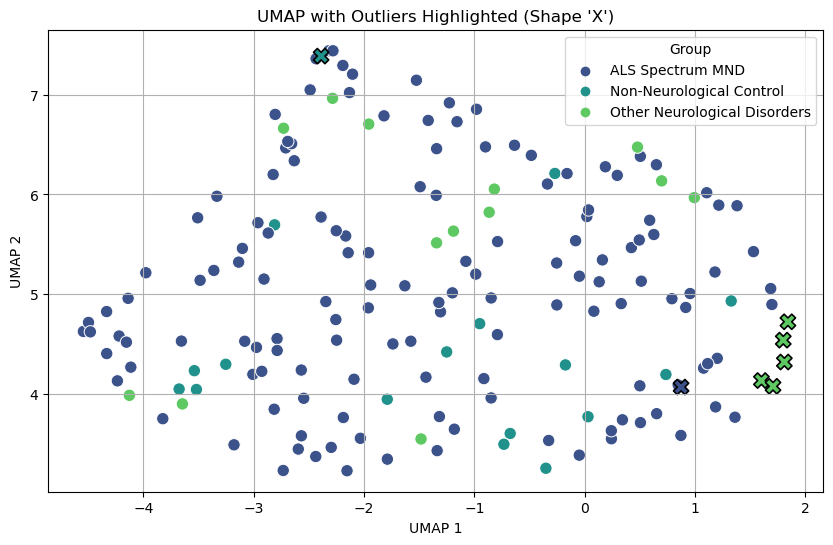

In [112]:
# Creating the UMAP DataFrame with group and outlier flag
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(scaled_data)
umap_df = pd.DataFrame(X_umap, columns=['UMAP1', 'UMAP2'], index=data_processor.get_data().index)
umap_df['Group'] = data_annotation['Sample_group'].values
umap_df['Outlier'] = umap_df.index.isin(outliers_visu.index)

# Separating normal points and outliers
umap_normal_df = umap_df[~umap_df['Outlier']]
umap_outlier_df = umap_df[umap_df['Outlier']]

# Plotting
plt.figure(figsize=(10, 6))

# Normal points
sns.scatterplot(
    data=umap_normal_df,
    x='UMAP1', y='UMAP2',
    hue='Group',
    palette='viridis',
    s=80,
    legend=True
)

# Outlier points (shape 'X', black border)
sns.scatterplot(
    data=umap_outlier_df,
    x='UMAP1', y='UMAP2',
    hue='Group',
    palette='viridis',
    s=120,
    legend=False,
    edgecolor='black',
    linewidth=1.2,
    marker='X'
)

plt.title("UMAP with Outliers Highlighted (Shape 'X')")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.grid(True)
plt.show()


## SubStep 3 : PCA Comparison with Umap and T-SNE

/opt/conda/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


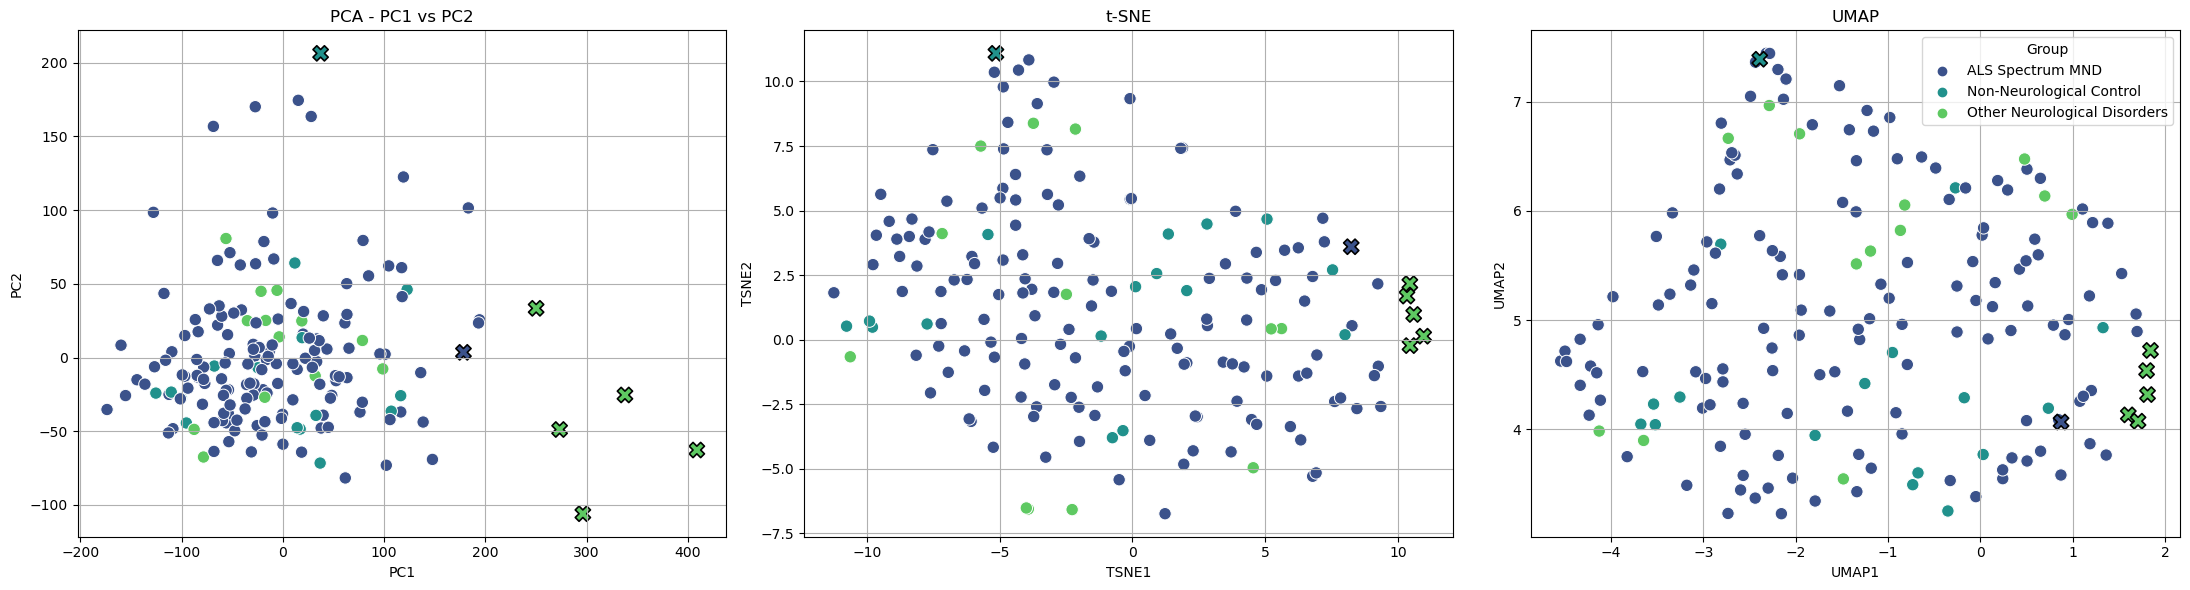

In [114]:

### --- PCA VISUALIZATION --- ###
pca_visu = PCA(n_components=4)  # Perform PCA with 4 components
pca_visu_result = pca_visu.fit_transform(scaled_data)  # Apply PCA

# Create DataFrame for PCA results with the first 4 components
pca_visu_df = pd.DataFrame(pca_visu_result, columns=[f'PC{i+1}' for i in range(4)], index=data_processor.get_data().index)
pca_visu_df['Group'] = data_annotation['Sample_group'].values  # Add group information
pca_visu_df['Distance'] = (pca_visu_df.iloc[:, :4]**2).sum(axis=1).pow(0.5)  # Calculate Euclidean distance in 4D PCA space

# Outlier detection based on threshold: mean + 2 * standard deviation
mean_dist = pca_visu_df['Distance'].mean()  # Calculate the mean of distances
std_dist = pca_visu_df['Distance'].std()    # Calculate the standard deviation of distances
threshold = mean_dist + 2 * std_dist  # Set the outlier threshold
outliers_visu = pca_visu_df[pca_visu_df['Distance'] > threshold]  # Identify outliers

pca_visu_df['Outlier'] = pca_visu_df.index.isin(outliers_visu.index)  # Add a column to flag outliers

# --- t-SNE --- #
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(scaled_data)  # Apply t-SNE with 2 components
tsne_df = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'], index=data_processor.get_data().index)  # Create DataFrame for t-SNE results
tsne_df['Group'] = data_annotation['Sample_group'].values  # Add group information
tsne_df['Outlier'] = tsne_df.index.isin(outliers_visu.index)  # Flag outliers

# --- UMAP --- #
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(scaled_data)  # Apply UMAP with 2 components
umap_df = pd.DataFrame(X_umap, columns=['UMAP1', 'UMAP2'], index=data_processor.get_data().index)  # Create DataFrame for UMAP results
umap_df['Group'] = data_annotation['Sample_group'].values  # Add group information
umap_df['Outlier'] = umap_df.index.isin(outliers_visu.index)  # Flag outliers

# === COMPARATIVE VISUALIZATION === #
fig, axs = plt.subplots(1, 3, figsize=(22, 6))  # Create a 1x3 grid for side-by-side plots

# PCA plot (PC1 vs PC2)
sns.scatterplot(
    data=pca_visu_df[~pca_visu_df['Outlier']],  # Plot data points that are not outliers
    x='PC1', y='PC2',
    hue='Group', palette='viridis', s=80, ax=axs[0], legend=False  # Color by group and set the marker size
)
sns.scatterplot(
    data=pca_visu_df[pca_visu_df['Outlier']],  # Plot the outliers with 'X' markers
    x='PC1', y='PC2',
    hue='Group', palette='viridis', s=120,
    marker='X', edgecolor='black', linewidth=1.2, ax=axs[0], legend=False  # Outliers with black border
)
axs[0].set_title("PCA - PC1 vs PC2")  # Set title for PCA plot

# t-SNE plot
sns.scatterplot(
    data=tsne_df[~tsne_df['Outlier']],  # Plot non-outlier data points
    x='TSNE1', y='TSNE2',
    hue='Group', palette='viridis', s=80, ax=axs[1], legend=False  # Color by group and set the marker size
)
sns.scatterplot(
    data=tsne_df[tsne_df['Outlier']],  # Plot the outliers with 'X' markers
    x='TSNE1', y='TSNE2',
    hue='Group', palette='viridis', s=120,
    marker='X', edgecolor='black', linewidth=1.2, ax=axs[1], legend=False  # Outliers with black border
)
axs[1].set_title("t-SNE")  # Set title for t-SNE plot

# UMAP plot
sns.scatterplot(
    data=umap_df[~umap_df['Outlier']],  # Plot non-outlier data points
    x='UMAP1', y='UMAP2',
    hue='Group', palette='viridis', s=80, ax=axs[2], legend='full'  # Color by group and set the marker size
)
sns.scatterplot(
    data=umap_df[umap_df['Outlier']],  # Plot the outliers with 'X' markers
    x='UMAP1', y='UMAP2',
    hue='Group', palette='viridis', s=120,
    marker='X', edgecolor='black', linewidth=1.2, ax=axs[2], legend=False  # Outliers with black border
)
axs[2].set_title("UMAP")  # Set title for UMAP plot

# Add grid and adjust layout
for ax in axs:
    ax.grid(True)

plt.tight_layout()  # Ensure proper spacing between subplots
plt.show()  # Display the plots


In the visualization, the comparison of PCA, t-SNE, and UMAP reveals the strengths and differences between these dimensionality reduction techniques.


### PCA (left plot): 

PCA focuses on the linear combinations of the original features that explain the largest variance. 

It shows a somewhat spread-out distribution of the samples, where the variance captured by the first two principal components (PC1 and PC2) accounts for 28.8% and 9.8% of the total variance, respectively. The samples from the same group (ALS Spectrum MND, Non-Neurological Control, and Other Neurological Disorders) are mostly mixed, showing partial separations based on their characteristics but no clear distinction.


### t-SNE (middle plot): 

t-SNE performs non-linear dimensionality reduction and is better at preserving local structures, such as clusters and similarities between nearby samples. 

In this plot, the groups appear more distinct and somewhat clustered, especially for the Non-Neurological Control (yellow), suggesting that t-SNE is good at separating groups that are more similar to each other. However, the global distances may be distorted, making it difficult to interpret the overall data structure compared to PCA.






### UMAP (right plot): 

UMAP, like t-SNE, captures local structure but also preserves more of the global relationships. It provides a clearer separation of the groups, especially ALS Spectrum MND (purple) and Non-Neurological Control (yellow). UMAP appears to offer better separation between groups compared to t-SNE, with more compact clusters, and unlike t-SNE, it retains some global structure, making it easier to compare samples across different groups.


### Conclusion: While PCA is useful for visualizing the overall variance and structure of the data, UMAP provides a better separation of the groups with a more interpretable structure. t-SNE, though excellent at clustering similar samples, distorts global relationships, which makes it harder to compare the overall distribution of groups. Therefore, for better visualization of distinct groupings in this dataset, UMAP seems to provide the most meaningful insights.




# Step 5 - Univariate Analysis

## Substep 1 : Preparing the Data

In [38]:
# Aligning the data and annotations using 'Sample_id'
data_annotation.set_index('Sample_id', inplace=True)  # Set 'Sample_id' as the index for annotations
data = data.set_index(data_annotation.index)  # Align the data's index to the annotations

## Substep 2 : Initializing DESeq2 with the Data

In [40]:

# Initialize DeseqDataSet with the aligned data
inference = DefaultInference(n_cpus=1)  # Set to 1 CPU for this analysis (can increase for larger datasets)
dds = DeseqDataSet(
    counts=data,  # Gene expression data (samples x genes)
    metadata=data_annotation,  # Annotations (metadata)
    design="~Sample_group",  # Design formula for differential analysis
    refit_cooks=True,  # Refitting the data for better precision
    inference=inference,  # Set inference object for statistical analysis
)

In [41]:
dds

AnnData object with n_obs × n_vars = 176 × 28953
    obs: 'Sample_group', 'Tissue_type', 'Cns_subregion', 'Subject_id'
    obsm: 'design_matrix'

In [42]:
dds. deseq2()

Fitting size factors...


Using None as control genes, passed at DeseqDataSet initialization


... done in 0.34 seconds.

Fitting dispersions...
... done in 37.23 seconds.

Fitting dispersion trend curve...
... done in 0.79 seconds.

Fitting MAP dispersions...
... done in 49.56 seconds.

Fitting LFCs...
... done in 17.77 seconds.

Calculating cook's distance...
... done in 0.71 seconds.

Replacing 221 outlier genes.

Fitting dispersions...
... done in 0.55 seconds.

Fitting MAP dispersions...
... done in 0.69 seconds.

Fitting LFCs...
... done in 0.30 seconds.



In [46]:
contrast = ["Sample_group", "ALS Spectrum MND", "Non-Neurological Control"]


deseq_stats = DeseqStats (dds, contrast, inference=inference)
# Set up DESeqSta

# Run the Wald test for statistical significance a
deseq_stats. run_wald_test()
deseq_stats.summary() # Print a summary of the results
# Store the results (including p-values, log fold changes, etc.) in a DataFran
results = deseq_stats. results_df

The history saving thread hit an unexpected error (OperationalError('disk I/O error')).History will not be written to the database.


Running Wald tests...


Log2 fold change & Wald test p-value: Sample_group ALS Spectrum MND vs Non-Neurological Control
                           baseMean  log2FoldChange     lfcSE      stat  \
A1BG                      35.993902       -0.018089  0.142837 -0.126642   
A1BG-AS1                 113.742747       -0.052983  0.099893 -0.530397   
A1CF                       0.155759        0.590130  1.708649  0.345378   
A2M                     2345.384523       -0.119104  0.159463 -0.746904   
A2M-AS1                   99.268405        0.186492  0.098238  1.898372   
...                             ...             ...       ...       ...   
X8_LINE:CR1:LINE         458.855014       -0.058600  0.103845 -0.564304   
X9_LINE:L1:LINE          109.576015        0.073882  0.111311  0.663748   
Zaphod2:hAT-Tip100:DNA   411.010268       -0.065308  0.105927 -0.616537   
Zaphod3:hAT-Tip100:DNA  1539.491230       -0.107348  0.107400 -0.999510   
Zaphod:hAT-Tip100:DNA   1710.104347       -0.084253  0.097368 -0.865302   

   

... done in 6.25 seconds.



In [47]:
# Sorting by p-value and select the first 100 genes
top_100_genes_sorted = results.sort_values('pvalue').head(100)

# Printing the sorted first 100 genes
top_100_genes_sorted

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ANKRD20A9P,12.357415,-2.019904,0.266522,-7.578740,3.489269e-14,8.383667e-10
MAPK8IP1P2,45.719131,4.562159,0.682360,6.685851,2.295860e-11,2.758131e-07
ZNF251,330.458494,-0.439164,0.075337,-5.829302,5.565971e-09,4.457786e-05
TBX3,58.858882,-1.402718,0.251549,-5.576317,2.456640e-08,1.315774e-04
CCL8,1.094456,-3.087393,0.555546,-5.557407,2.738115e-08,1.315774e-04
...,...,...,...,...,...,...
ASB16,4.451616,-0.976792,0.217583,-4.489285,7.146271e-06,1.788578e-03
IGSF22,28.638811,-0.823936,0.183807,-4.482619,7.373243e-06,1.826360e-03
FCHSD1,121.615032,-0.784751,0.175191,-4.479412,7.484878e-06,1.835094e-03
H2AFV,4264.481740,0.269522,0.060415,4.461157,8.151830e-06,1.978424e-03


In [50]:
top_100_genes_sorted.to_csv('top_100_genes_sorted.csv')


## Substep 4 : Running the Differential Expression Analysis

Now, we run the Wald test to identify genes that show significant differences in expression between the ALS and control groups.

## SubStep 5 : Visualization of Results - Volcano Plot

In [70]:
results = deseq_stats.results_df  # Try directly accessing results from the results_df attribute

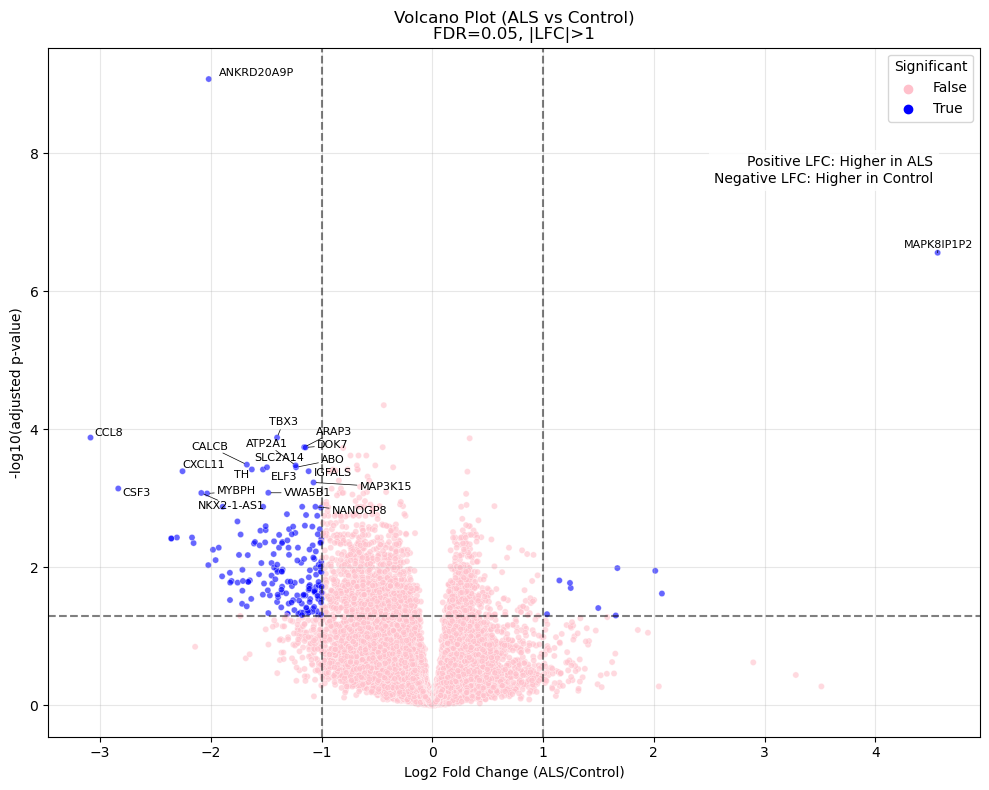

In [106]:
def plot_volcano(results, outliers_visu, padj_thresh=0.05, lfc_thresh=1, top_n=20):
    """
    Create a volcano plot from DESeq2 results and highlight outliers with a cross ('X').
    
    Parameters:
    - results: DataFrame from DESeq2 analysis
    - outliers_visu: DataFrame containing outlier information
    - padj_thresh: adjusted p-value threshold for significance
    - lfc_thresh: absolute log2 fold change threshold for significance
    - top_n: number of top genes to label
    """
    plt.figure(figsize=(10, 8))
    
    # Create a copy to avoid SettingWithCopyWarning
    plot_data = results.copy()
    
    # Original significance definition 
    plot_data['significant'] = (plot_data['padj'] < padj_thresh) & \
                              (abs(plot_data['log2FoldChange']) > lfc_thresh)
    
    # Calculate the -log10 of the adjusted p-values for visualization
    plot_data['neg_log10_padj'] = -np.log10(plot_data['padj'])
    
    # Original scatter plot for significant genes
    sns.scatterplot(
        data=plot_data,
        x='log2FoldChange',
        y='neg_log10_padj',
        hue='significant',
        palette={True: 'blue', False: 'pink'},
        alpha=0.6,
        s=20
    )
    
    # Add threshold lines 
    plt.axhline(-np.log10(padj_thresh), linestyle='--', color='black', alpha=0.5)
    plt.axvline(lfc_thresh, linestyle='--', color='black', alpha=0.5)
    plt.axvline(-lfc_thresh, linestyle='--', color='black', alpha=0.5)
    
    # Add labels for top significant genes
    significant_genes = plot_data[plot_data['significant']].copy()
    significant_genes['abs_lfc'] = abs(significant_genes['log2FoldChange'])
    top_genes = significant_genes.sort_values(['padj', 'abs_lfc']).head(top_n)
    
    # Add labels for the top significant genes
    texts = []
    for i, row in top_genes.iterrows():
        texts.append(plt.text(row['log2FoldChange'], 
                            row['neg_log10_padj'], 
                            i,
                            fontsize=8))
    if texts:
        adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))
    
    # Ensure outliers_visu contains 'log2FoldChange' and 'padj' from results
    # Align indices between outliers_visu and results
    outliers_visu = outliers_visu[outliers_visu.index.isin(results.index)]  # Only keep matching indices
    outliers_visu['log2FoldChange'] = results.loc[outliers_visu.index, 'log2FoldChange']
    outliers_visu['padj'] = results.loc[outliers_visu.index, 'padj']
    
    # Highlight the outliers with 'X' markers
    sns.scatterplot(
        data=outliers_visu, 
        x='log2FoldChange', 
        y=-np.log10(outliers_visu['padj']),
        color='green', 
        marker='X', 
        s=100, 
        label='Outliers'
    )
    
    # Add title and labels
    plt.title(f'Volcano Plot (ALS vs Control)\nFDR={padj_thresh}, |LFC|>{lfc_thresh}')
    plt.xlabel('Log2 Fold Change (ALS/Control)')
    plt.ylabel('-log10(adjusted p-value)')
    
    plt.text(0.95, 0.8, 
             'Positive LFC: Higher in ALS\nNegative LFC: Higher in Control',
             transform=plt.gca().transAxes,
             ha='right', va='bottom',
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    
    plt.legend(title='Significant')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Call the function with the results and outliers_visu
plot_volcano(results, outliers_visu)


In [107]:
log2_fc_threshold = 1  # Log2 fold change threshold
pval_threshold = 0.05  # P-value threshold (adjusted)

# Applying the thresholds from the volcano plot
significant_genes = results[(abs(results['log2FoldChange']) > log2_fc_threshold) & (results['padj'] < pval_threshold)]


# Printing out the significant genes
significant_genes.sort_values('pvalue').head(100)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ANKRD20A9P,12.357415,-2.019904,0.266522,-7.578740,3.489269e-14,8.383667e-10
MAPK8IP1P2,45.719131,4.562159,0.682360,6.685851,2.295860e-11,2.758131e-07
TBX3,58.858882,-1.402718,0.251549,-5.576317,2.456640e-08,1.315774e-04
CCL8,1.094456,-3.087393,0.555546,-5.557407,2.738115e-08,1.315774e-04
ARAP3,132.354075,-1.157553,0.213015,-5.434132,5.506372e-08,1.812318e-04
...,...,...,...,...,...,...
CDC42BPG,2.725452,-1.002000,0.276183,-3.628033,2.855892e-04,1.172421e-02
KIAA0087,0.746622,-1.828953,0.505512,-3.618018,2.968682e-04,1.198093e-02
MIR4673,0.826111,-1.565713,0.434864,-3.600465,3.176491e-04,1.255289e-02
LRRC14B,2.830418,-1.050253,0.292186,-3.594464,3.250598e-04,1.274957e-02


In [108]:
significant_genes.to_csv('significant_genes.csv')


# Step 6 : Multivariate Analysis - Elastic-Net 

## Elastic-Net implementation 

Since Elastic-Net is sensitive to the scale of features, we need to standardize the data to have mean zero and unit variance for each gene.

In [116]:
from sklearn.preprocessing import StandardScaler

# Assuming data_processor.get_data() returns the feature data (e.g., gene expression)
# And data_annotation['Sample_group'] contains the labels (e.g., ALS, Control)

# Standardize the features
X = StandardScaler().fit_transform(data_processor.get_data())  # X contains the RNA counts for all genes
y = data_annotation['Sample_group']  # y contains the group labels (e.g., ALS, Control)

# Optional: Recode the target variable if necessary (combine 'Other Neurological Disorders' with 'Non-Neurological Control')
y_combined = y.replace({'Other Neurological Disorders': 'Non-Neurological Control'})


Now that we have standardized data, we can set up the Elastic-Net logistic regression. We'll start by applying a basic Elastic-Net model with regularization.

In [117]:


# Initialize Elastic-Net logistic regression model
elasticNet = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=0.5, class_weight='balanced')

# Fit the model on the data
elasticNet.fit(X, y_combined)

# Evaluate the model (make predictions and calculate accuracy)
model_predictions = elasticNet.predict(X)  # Predictions on the training data
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_combined, model_predictions)

print("Accuracy on raw data: ", accuracy)


Accuracy on raw data:  1.0


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


## Fine tuning of parameters 

We want to fine-tune the Elastic-Net model by using cross-validation to select the best hyperparameters (l1_ratio and C).

In [120]:
# Fine-tune parameters using cross-validation
elasticNet_cv = LogisticRegressionCV(
    penalty='elasticnet',
    cv=3,  # Cross-validation with 3 folds
    solver='saga',
    l1_ratios=[0.25, 0.5, 0.75, 0.9],  # Explore different l1/l2 ratios
    Cs=[0.1, 0.5, 1],  # Regularization strength (inverse of C)
    scoring='accuracy',  # Use accuracy for evaluation
    class_weight='balanced'  # Handle class imbalance
)

# Fit the model with cross-validation
elasticNet_cv.fit(X, y_combined)

# Check the best parameters found through cross-validation
print("Best L1 ratio:", elasticNet_cv.l1_ratio_)
print("Best C:", elasticNet_cv.C_)

# Evaluate the model with the best parameters
model_predictions_cv = elasticNet_cv.predict(X)
accuracy_cv = accuracy_score(y_combined, model_predictions_cv)

print("Accuracy after cross-validation: ", accuracy_cv)


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which 

Best L1 ratio: [0.9]
Best C: [0.1]
Accuracy after cross-validation:  0.9375


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


## Testing our Model

Now that we have a fine-tuned model, we need to evaluate its performance on unseen data (test set). To do this, we need to split the data into a training and a test set.

In [122]:


# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_combined, test_size=0.4, random_state=42)

# Train the fine-tuned Elastic-Net model
elasticNet_cv.fit(X_train, y_train)

# Make predictions on the test set
y_pred_test = elasticNet_cv.predict(X_test)

# Evaluate the model's performance on the test set
from sklearn.metrics import classification_report, balanced_accuracy_score, f1_score

print("Classification Report on Test Set:")
print(classification_report(y_test, y_pred_test))

# Compute balanced accuracy score
print("Balanced Accuracy Score on Test Set:", balanced_accuracy_score(y_test, y_pred_test))

# Compute the F1-score (weighted average)
print("F1 Score (Weighted):", f1_score(y_test, y_pred_test, average='weighted'))


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which 

Classification Report on Test Set:
                          precision    recall  f1-score   support

        ALS Spectrum MND       0.91      0.67      0.77        60
Non-Neurological Control       0.26      0.64      0.37        11

                accuracy                           0.66        71
               macro avg       0.58      0.65      0.57        71
            weighted avg       0.81      0.66      0.71        71

Balanced Accuracy Score on Test Set: 0.6515151515151515
F1 Score (Weighted): 0.7071334891942749


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


We can see that the model performs well in terms of precision for the ALS group (0.91), indicating it correctly identifies ALS samples when it predicts them. However, its recall for ALS is low (0.67), meaning it misses about a third of actual ALS cases.

For the control group, recall is high (0.64), but precision is low (0.26), meaning the model incorrectly classifies many ALS samples as control.

The overall accuracy is 66%, which is decent but could be improved. The balanced accuracy score of 0.65 reflects the model's tendency to favor the larger ALS group, given the class imbalance.

In conclusion, the model is better at identifying ALS samples but struggles with correctly classifying the smaller control group. 


## Selecting the best genes 

In [142]:
# Get the coefficients of the trained model (importance of each gene)
coefficients = elasticNet_cv.coef_

# Rank the genes by their absolute coefficient values to find the most relevant genes
gene_importance = np.abs(coefficients).flatten()  # Flatten the coefficients array

sorted_gene_indices = np.argsort(gene_importance)[::-1]  # Sort genes by importance (high to low)


gene_names = data.columns
top_100_genes = pd.DataFrame({'Gene': gene_names, 'Coefficient': coefficients.flatten()})
top_100_genes_sorted = top_100_genes.reindex(top_100_genes['Coefficient'].abs().sort_values(ascending=False).index)

# Save to CSV
top_100_genes_sorted.head(100).to_csv('top_100_genes.csv', index=False)

# Conclusion 

This project focused on the analysis of RNA-Seq data from post-mortem brain cortex biopsies of individuals diagnosed with Amyotrophic Lateral Sclerosis (ALS) and healthy controls, aiming to identify potential biomarkers for ALS. Key steps included data preprocessing, differential expression analysis, and dimensionality reduction using PCA, t-SNE, and UMAP for visualizing gene expression patterns. The data showed significant inter-gene variability, and the PCA, t-SNE, and UMAP visualizations highlighted distinct clustering of ALS and control groups.

Elastic-Net regression was applied for feature selection, and through cross-validation, the model demonstrated a high precision for identifying ALS samples (91%), though its recall for ALS was lower (67%), indicating that it missed a portion of true ALS cases. For the control group, the recall was higher (64%), but precision was low (26%), suggesting issues with misclassification of ALS samples as controls.

The differential expression analysis revealed several genes with significant changes in expression between ALS and control samples, with the top 100 most important genes identified based on their coefficients in the Elastic-Net model. These genes offer promising candidates for further exploration in ALS biomarker discovery.

Overall, while the model performed well in distinguishing ALS from controls, there is still room for improvement in addressing class imbalance and enhancing the model's recall for control samples.

